# Day 22

In [5]:
import nltk
import os

In [ ]:
nltk.download()

In [6]:
print(os.listdir(nltk.data.find('corpora')))

['abc.zip', 'shakespeare.zip', 'mte_teip5.zip', 'pros_cons', 'framenet_v15', 'conll2000.zip', 'unicode_samples.zip', 'opinion_lexicon.zip', 'timit', 'ieer.zip', 'panlex_swadesh.zip', 'cess_cat.zip', 'product_reviews_1.zip', 'machado.zip', 'mock_corpus', 'verbnet3.zip', 'propbank.zip', 'floresta', 'city_database.zip', 'pros_cons.zip', 'pe08', 'cess_esp.zip', 'udhr2', 'stopwords.zip', 'movie_reviews', 'webtext', 'udhr.zip', 'problem_reports', 'mac_morpho', 'alpino.zip', 'sinica_treebank', 'crubadan.zip', 'pil', 'inaugural.zip', 'state_union', 'gutenberg', 'kimmo.zip', 'swadesh', 'product_reviews_2.zip', 'framenet_v17.zip', 'chat80.zip', 'conll2007.zip', 'words', 'udhr', 'mac_morpho.zip', 'biocreative_ppi', 'lin_thesaurus.zip', 'semcor.zip', 'cmudict', 'europarl_raw.zip', 'cmudict.zip', 'wordnet_ic.zip', 'kimmo', 'omw-2.0.zip', 'webtext.zip', 'brown', 'europarl_raw', 'dolch', 'ycoe.zip', 'knbc.zip', 'unicode_samples', 'mock_corpus.zip', 'product_reviews_2', 'smultron.zip', 'nonbreaking_pr

In [7]:
nltk.data.find('corpora')

FileSystemPathPointer('/home/coder/nltk_data/corpora')

In [24]:
from wordcloud import WordCloud, STOPWORDS
import pandas
import string
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, TfidfVectorizer

In [15]:
df = pandas.read_csv('./data/SMSSpamCollection1.tsv',sep='\t',names=['class','message'])
df

,class,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [16]:
df[:2]

,class,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...


In [17]:
df.groupby('class').describe()

message                                                               
        count unique                                                top freq
class                                                                       
ham      4825   4516                             Sorry, I'll call later   30
spam      747    653  Please call our customer service representativ...    4

In [18]:
length_msg = df['message'].apply(len)

In [19]:
df['length'] = length_msg

In [20]:
df

,class,message,length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61
...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,160
5568,ham,Will ü b going to esplanade fr home?,36
5569,ham,"Pity, * was in mood for that. So...any other s...",57
5570,ham,The guy did some bitching but I acted like i'd...,125


<Axes: ylabel='Frequency'>

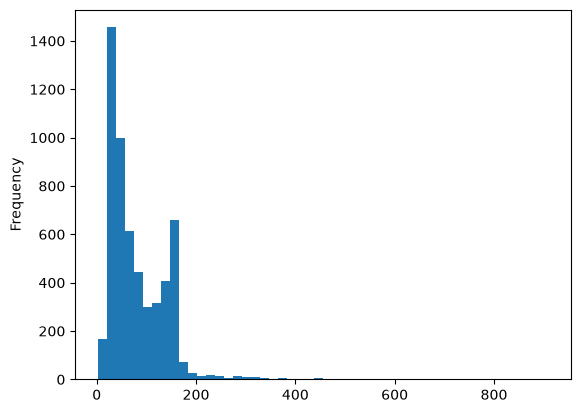

In [21]:
df['length'].plot(bins=50,kind='hist')

In [25]:
def cleaning(msg):
    punc = string.punctuation
    not_punc = ''.join([word for word in msg if word not in punc])
    return ([word for word in not_punc.split() if word.lower() not in STOPWORDS])

In [26]:
vect = CountVectorizer(analyzer=cleaning).fit(df['message'])

In [32]:
len(vect.vocabulary_)

11420

In [36]:
v1 = vect.transform([df['message'][3]])
v1

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 7 stored elements and shape (1, 11420)>

In [37]:
print(v1)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 7 stored elements and shape (1, 11420)>
  Coords	Values
  (0, 4060)	2
  (0, 4625)	1
  (0, 5256)	1
  (0, 6199)	1
  (0, 6217)	1
  (0, 7177)	1
  (0, 9547)	2


In [42]:
print(vect.get_feature_names_out()[7177])

hor


In [43]:
msgs_vect = vect.transform(df['message'])

In [44]:
msgs_vect.shape

(5572, 11420)

In [45]:
msgs_vect.nnz

50536

In [47]:
tfidf1 = TfidfTransformer().fit(msgs_vect)
tfidf1

TfidfTransformer()

In [48]:
tfidf2 = tfidf1.transform(msgs_vect)
tfidf2

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 50536 stored elements and shape (5572, 11420)>

### IMDB Dataset